Data path: ..\data\pima-indians-diabetes.csv
Shape: (768, 9)

Class distribution (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64

Missing values (%):
Pregnancies                  0.0
Glucose                      0.7
BloodPressure                4.6
SkinThickness               29.6
Insulin                     48.7
BMI                          1.4
DiabetesPedigreeFunction     0.0
Age                          0.0
Outcome                      0.0
dtype: float64
Train: (614, 8)
Test:  (154, 8)

Train positive rate: 0.349
Test positive rate:  0.351
Train CV metrics:


,threshold,precision,recall,f1,roc_auc,accuracy
model,,,,,,
LogisticRegression,0.4011,0.5789,0.8224,0.6795,0.8441,0.7296
RandomForest,0.3529,0.5710,0.8645,0.6877,0.8285,0.7264



Selected model: RandomForest
Selected threshold: 0.3529
Test metrics:
threshold: 0.3529
accuracy: 0.7143
precision: 0.5625
recall: 0.8333
f1: 0.6716
roc_auc: 0.8209

Classification report:
              precision    recall  f1-score   support

 No Diabetes      0.878     0.650     0.747       100
    Diabetes      0.562     0.833     0.672        54

    accuracy                          0.714       154
   macro avg      0.720     0.742     0.709       154
weighted avg      0.768     0.714     0.721       154



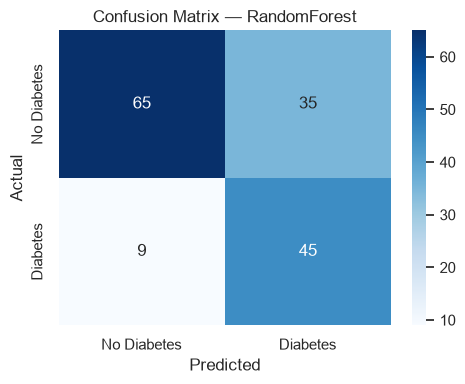

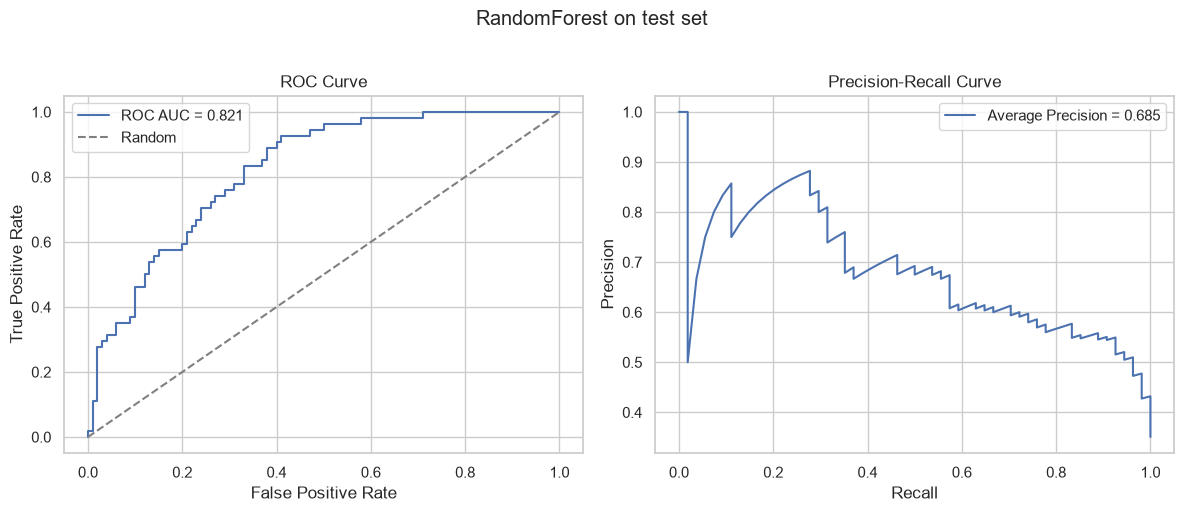

Pipeline saved to: models\diabetes_randomforest_pipeline.joblib
Metrics saved to: models\test_metrics.json


In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
    average_precision_score,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TEST_SIZE = 0.20
MIN_RECALL = 0.80

# %%
data_paths = [
    Path("../data/pima-indians-diabetes.csv"),
    Path("data/pima-indians-diabetes.csv"),
    Path("../pima-indians-diabetes.csv"),
]
data_path = next((p for p in data_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("pima-indians-diabetes.csv не найден")

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df = pd.read_csv(data_path, names=columns)
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

print(f"Data path: {data_path}")
print(f"Shape: {df.shape}")
print("\nClass distribution (%):")
print((df["Outcome"].value_counts(normalize=True) * 100).round(2))
print("\nMissing values (%):")
print((df.isna().mean() * 100).round(1))

# %%
X = df.drop(columns="Outcome")
y = df["Outcome"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")
print(f"\nTrain positive rate: {y_train.mean():.3f}")
print(f"Test positive rate:  {y_test.mean():.3f}")

# %%
def build_pipeline(model):
    return Pipeline([
        ("imputer", KNNImputer(n_neighbors=5)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])


models = {
    "LogisticRegression": lambda: LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "RandomForest": lambda: RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

# %%
def choose_threshold(y_true, y_prob, min_recall=MIN_RECALL):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)

    if thresholds.size == 0:
        return 0.5

    p, r = precision[:-1], recall[:-1]
    denom = p + r
    f1 = np.divide(2 * p * r, denom, out=np.zeros_like(denom, dtype=float), where=denom != 0)

    ok = r >= min_recall
    if ok.any():
        scores = np.where(ok, f1, -np.inf)
    else:
        scores = np.where(np.isclose(r, r.max()), f1, -np.inf)

    return float(thresholds[np.argmax(scores)])


def get_metrics(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, y_prob)),
    }

# %%
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, make_model in models.items():
    proba = cross_val_predict(
        build_pipeline(make_model()),
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
    )[:, 1]

    threshold = choose_threshold(y_train.to_numpy(), proba)
    rows.append({"model": name, **get_metrics(y_train.to_numpy(), proba, threshold)})

cv_df = pd.DataFrame(rows).set_index("model")

print("Train CV metrics:")
display(cv_df[["threshold", "precision", "recall", "f1", "roc_auc", "accuracy"]].round(4))

best_name = cv_df.sort_values(["f1", "recall"], ascending=False).index[0]
best_threshold = float(cv_df.loc[best_name, "threshold"])

print(f"\nSelected model: {best_name}")
print(f"Selected threshold: {best_threshold:.4f}")

# %%
final_pipeline = build_pipeline(models[best_name]())
final_pipeline.fit(X_train, y_train)

test_proba = final_pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)
test_metrics = get_metrics(y_test.to_numpy(), test_proba, best_threshold)

print("Test metrics:")
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test, test_pred, target_names=["No Diabetes", "Diabetes"], digits=3
    )
)

# %%
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

# %%
fpr, tpr, _ = roc_curve(y_test, test_proba)
precision, recall, _ = precision_recall_curve(y_test, test_proba)
roc_auc = roc_auc_score(y_test, test_proba)
avg_precision = average_precision_score(y_test, test_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

axes[1].plot(recall, precision, label=f"Average Precision = {avg_precision:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.suptitle(f"{best_name} on test set", y=1.02)
plt.tight_layout()
plt.show()

# %%
model_dir = Path("../models")
if not model_dir.exists():
    model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

pipeline_path = model_dir / f"diabetes_{best_name.lower().replace(' ', '_')}_pipeline.joblib"
metrics_path = model_dir / "test_metrics.json"

joblib.dump(final_pipeline, pipeline_path)

artifacts = {
    "best_model": best_name,
    "threshold": best_threshold,
    "test_metrics": test_metrics,
    "confusion_matrix": cm.tolist(),
    "target_names": ["No Diabetes", "Diabetes"],
    "feature_names": X.columns.tolist(),
}
metrics_path.write_text(json.dumps(artifacts, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Pipeline saved to: {pipeline_path}")
print(f"Metrics saved to: {metrics_path}")